# Phylogenetic Analysis of Anatomical Constraints
This notebook aggregates anatomical data (specifically the $V_{BS/M}$ ratio) across different photosynthetic types, constructs a phylogenetic tree using NCBI taxonomy, and visualizes the distribution of these traits on the tree.

## 1. Imports

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import to_hex
from seaborn import color_palette
from ete3 import NCBITaxa, TreeStyle, AttrFace, faces, NodeStyle, TextFace, Tree
from IPython.display import SVG, display,  HTML


## 2. Data Preparation and Filtering
Aggregating data from C3, C3-C4, and C4 species files, calculating mean $V_{BS/M}$ values per species, and merging them into a single dataset.

In [26]:
# Define file paths
path_c3 = "../Datasets/Phylo_Tree_C3_Without_Outliers.csv"
path_c3_c4 = "../Datasets/Phylo_Tree_C3_C4_Without_Outliers.csv"
path_c4 = "../Datasets/Phylo_Tree_C4_Without_Outliers.csv"
output_path = "../Datasets/Phylo_Tree_Data_Compiled_Filtered.csv"

# Process C3 Data
try:
    df_C3 = pd.read_csv(path_c3)
    df_c3_filtered = df_C3.groupby('Species')['AW_BS/AW_M'].mean().reset_index()
    df_c3_filtered.rename(columns={'AW_BS/AW_M': "V_BS_M"}, inplace=True)
    df_c3_filtered["Photosynthesis"] = "C3"
except FileNotFoundError:
    print(f"Warning: {path_c3} not found. Skipping C3 data.")
    df_c3_filtered = pd.DataFrame()

# Process C3-C4 Data
try:
    df_C3_C4 = pd.read_csv(path_c3_c4)
    df_C3_C4_filtered = df_C3_C4.groupby('Species')['AW_BS/AW_M'].mean().reset_index()
    df_C3_C4_filtered.rename(columns={'AW_BS/AW_M': "V_BS_M"}, inplace=True)
    df_C3_C4_filtered["Photosynthesis"] = "C3-C4"
except FileNotFoundError:
    print(f"Warning: {path_c3_c4} not found. Skipping C3-C4 data.")
    df_C3_C4_filtered = pd.DataFrame()

# Process C4 Data
try:
    df_C4 = pd.read_csv(path_c4)
    df_C4_filtered = df_C4.groupby('Species')['AW_BS/AW_M'].mean().reset_index()
    df_C4_filtered.rename(columns={'AW_BS/AW_M': "V_BS_M"}, inplace=True)
    df_C4_filtered["Photosynthesis"] = "C4"
except FileNotFoundError:
    print(f"Warning: {path_c4} not found. Skipping C4 data.")
    df_C4_filtered = pd.DataFrame()

# Concatenate and Save
phylo_data_filtered = pd.concat([df_c3_filtered, df_C3_C4_filtered, df_C4_filtered], ignore_index=True)
print("Aggregated Data Head:")
print(phylo_data_filtered.head())

# Save to CSV (using comma separator for consistency)
phylo_data_filtered.to_csv(output_path, sep=",", index=False)

Aggregated Data Head:
                    Species    V_BS_M Photosynthesis
0       Anticharis scoparia  0.943870             C3
1    Chenopodium atrovirens  0.437566             C3
2         Chenopodium hians  0.632800             C3
3       Chenopodium incanum  1.309857             C3
4  Chenopodium leptophyllum  1.147443             C3


## 3. Phylogenetic Tree Construction
Building the phylogenetic tree using the `ete3` library and NCBI Taxonomy database. The tree is annotated with species names, photosynthetic types (branch colors), and $V_{BS/M}$ ratios (outer ring grayscale).

In [27]:
# Load the filtered data
data = pd.read_csv("../Datasets/Phylo_Tree_Data_Compiled_Filtered.csv", sep=",")

# Initialize NCBI Taxa (requires local database setup on first run)
ncbi = NCBITaxa()

# Get the taxids for each species
taxid_dict = {species: ncbi.get_name_translator([species]).get(species, [None])[0] for species in data['Species']}
# Filter out species not found in NCBI database
valid_taxids = [taxid for taxid in taxid_dict.values() if taxid]

if not valid_taxids:
    print("No valid taxids found. Please check species names or NCBI database.")
else:
    # Build the tree topology
    tree = ncbi.get_topology(valid_taxids)

    # Define photosynthetic type colors
    type_colors = {'C3': '#3274a1', 'C3-C4': '#e1812c', 'C4': '#3a923a'}

    # Define V_BS_M color scale
    norm = plt.Normalize(0, data['V_BS_M'].max())
    cmap = plt.cm.Greys

    # Define custom visualization function
    def layout(node):
        if node.is_leaf():
            # Retrieve the species name based on taxid
            species_candidates = [k for k, v in taxid_dict.items() if v == node.taxid]
            if not species_candidates:
                return
            species = species_candidates[0]
            
            node.name = node.sci_name  # Set the node's name to the species name

            # Get corresponding photosynthetic type and V_BS_M value
            species_data = data.loc[data['Species'] == species]
            if species_data.empty:
                return
                
            v_bs_m = species_data['V_BS_M'].values[0]
            photosynthetic_type = species_data['Photosynthesis'].values[0]
            
            # Add species name with extra spaces for padding
            name_face = TextFace("  " + species + "  ", fsize=12, fgcolor="black", bold=True)
            faces.add_face_to_node(name_face, node, column=0)
            
            # Color branch according to photosynthetic type
            node_style = NodeStyle()
            if photosynthetic_type in type_colors:
                color_hex = type_colors[photosynthetic_type]
                node_style["fgcolor"] = color_hex
                node_style["vt_line_color"] = color_hex
                node_style["hz_line_color"] = color_hex
            node_style["size"] = 0  # Hide node circle
            node.set_style(node_style)
            
            # Add V_BS_M ring with extra spaces for padding
            color = to_hex(cmap(norm(v_bs_m)))
            vbs_face = TextFace(" ", fsize=70)  # Increased spaces for padding
            vbs_face.background.color = color
            faces.add_face_to_node(vbs_face, node, column=1, position="aligned")
        else:
            # Internal node styling
            sci_name = node.sci_name if node.sci_name else ""
            taxonomic_face = TextFace(sci_name, fsize=10, fgcolor="black", bold=False)
            faces.add_face_to_node(taxonomic_face, node, column=0, position="branch-bottom")
            node.set_style(NodeStyle(size=0))

    # Set up the tree style
    ts = TreeStyle()
    ts.mode = "c"  # Circular mode
    ts.show_leaf_name = False
    ts.show_branch_support = False
    ts.layout_fn = layout
    ts.scale = 20 # Adjust scale for better visibility

    # Annotate and Render
    # ncbi.annotate_tree(tree, taxid_attr="name") # Optional, depending on ete3 version/setup
    
    output_image = "../Images/Phylo_Tree.svg"
    tree.render(output_image, tree_style=ts)
    print(f"Tree rendered to {output_image}")

Tree rendered to ../Images/Phylo_Tree.svg


## 4. Visualization Legend
Generating a colorbar to interpret the grayscale ring representing the $V_{BS/M}$ ratio.

Colorbar saved to ../Images/colorbar.svg


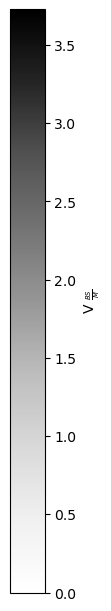

In [28]:
# Load data again to ensure context
data = pd.read_csv("../Datasets/Phylo_Tree_Data_Compiled_Filtered.csv", sep=",")

# Define V_BS_M color scale
norm = plt.Normalize(0, data['V_BS_M'].max())
cmap = plt.cm.Greys

fig, ax = plt.subplots(figsize=(1, 6), layout='constrained')

fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
             cax=ax, orientation='vertical', label=r'V $_{\frac{BS}{M}}$')

colorbar_path = "../Images/colorbar.svg"
fig.savefig(colorbar_path)
print(f"Colorbar saved to {colorbar_path}")

## 5. Display Results

Phylogenetic Tree:



V_BS/M Colorbar:


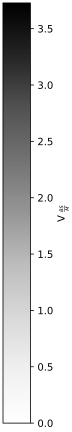

In [29]:
print("Phylogenetic Tree:")
display(HTML('<img src="../Images/Phylo_Tree.svg" width="1000" style="background-color:white">'))

print("\nV_BS/M Colorbar:")
display(SVG(filename="../Images/colorbar.svg"))